# Evaluasi Menyeluruh Model Gaussian Naïve Bayes
### Kasus Klasifikasi Klinis: Pima Indians Diabetes Database

---

## Ringkasan Evaluasi

Notebook ini dirancang secara sistematis untuk memfasilitasi evaluasi mendalam performa model **Gaussian Naïve Bayes** pada data klinis riil. Analisis berfokus pada:
1. **Validasi Teori Probabilitas**: Menilai implikasi pelanggaran *asumsi independensi bersyarat* pada fitur berkorelasi tinggi.
2. **Pemeriksaan Parameter Gauss**: Meninjau pemisahan distribusi $\mu_{kj}$ dan variansi $\sigma_{kj}^2$ antara pasien sehat dan diabetes.
3. **Evaluasi Matriks Konfusi & Metrik Klasifikasi**: Mengukur Akurasi, Presisi, Sensitivitas (*Recall*), dan Skor-F1.
4. **Analisis Kurva ROC, Precision-Recall, & Threshold Tuning**: Meneliti pergeseran ambang batas probabilitas $\tau$ untuk meminimalkan *False Negatives* (risiko keterlambatan terapi medis).
5. **Stabilitas Model (5-Fold Stratified Cross-Validation)**: Memverifikasi reliabilitas model melintasi subset data yang berbeda.
6. **Bedah Galat Kasus Khusus**: Mengidentifikasi karakteristik anomali pada sampel yang gagal diprediksi dengan benar.


In [1]:
# 1. Inisialisasi Lingkungan & Modul Modular
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Tambahkan direktori root proyek ke sys.path
ROOT_DIR = Path.cwd().resolve().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.data import ClinicalImputer, load_dataset, prepare_splits
from src.models import GaussianNBClassifier
from src.evaluation import evaluate_predictions, run_stratified_cv, analyze_errors
from src.visualization import (
    plot_confusion_matrix,
    plot_roc_and_pr_curves,
    plot_likelihood_distributions,
    plot_feature_correlations,
    plot_threshold_tuning,
    plot_cross_validation_stability
)

print("✓ Seluruh dependensi dan modul modular 'src' berhasil dimuat.")
print("✓ Parameter acak (random_state) dikunci pada nilai: 42.")

✓ Seluruh dependensi dan modul modular 'src' berhasil dimuat.
✓ Parameter acak (random_state) dikunci pada nilai: 42.


In [2]:
# 2. Ingesti & Pra-pemrosesan Data Klinis (Zero Data Leakage)
data_path = ROOT_DIR / "data" / "raw" / "diabetes_pima.csv"
df_raw = load_dataset(data_path)

X_train, X_test, y_train, y_test, feature_names = prepare_splits(
    df_raw, target_col="Outcome", test_size=0.20, random_state=42, impute_missing=True
)
df_clean = pd.concat(
    [pd.concat([X_train, y_train], axis=1), pd.concat([X_test, y_test], axis=1)]
).sort_index()

print("=" * 70)
print(" PROFIL DATASET PIMA INDIANS DIABETES")
print("=" * 70)
print(f"Total Pengamatan (n) : {len(df_raw)} baris")
print(f"Jumlah Fitur Prediktor: {df_raw.shape[1] - 1} kolom numerik kontinu/diskrit")
neg_c = (df_raw['Outcome'] == 0).sum()
pos_c = (df_raw['Outcome'] == 1).sum()
print(f"Distribusi Kelas 0   : {neg_c} sampel ({neg_c/len(df_raw)*100:.1f}%) [Non-Diabetes]")
print(f"Distribusi Kelas 1   : {pos_c} sampel ({pos_c/len(df_raw)*100:.1f}%) [Diabetes]")
print("-" * 70)
print("Imputasi Nilai Nol Biologis (Fit Khusus Data Latih — Zero Data Leakage):")
X_tr_raw, _, _, _, _ = prepare_splits(df_raw, target_col="Outcome", test_size=0.20, random_state=42, impute_missing=False)
imputer = ClinicalImputer().fit(X_tr_raw)
for col in ['Insulin', 'SkinThickness', 'BloodPressure', 'BMI', 'Glucose']:
    zeros = (df_raw[col] == 0).sum()
    med = imputer.medians_[col]
    print(f"• {col:<14}: {zeros} nilai nol terdeteksi, median latih = {med:.2f}")
print("=" * 70)

 PROFIL DATASET PIMA INDIANS DIABETES
Total Pengamatan (n) : 768 baris
Jumlah Fitur Prediktor: 8 kolom numerik kontinu/diskrit
Distribusi Kelas 0   : 500 sampel (65.1%) [Non-Diabetes]
Distribusi Kelas 1   : 268 sampel (34.9%) [Diabetes]
----------------------------------------------------------------------
Imputasi Nilai Nol Biologis (Fit Khusus Data Latih — Zero Data Leakage):
• Insulin       : 374 nilai nol terdeteksi, median latih = 126.00
• SkinThickness : 227 nilai nol terdeteksi, median latih = 29.00
• BloodPressure : 35 nilai nol terdeteksi, median latih = 72.00
• BMI           : 11 nilai nol terdeteksi, median latih = 32.00
• Glucose       : 5 nilai nol terdeteksi, median latih = 118.00


## 1. Inspeksi Distribusi Kerapatan Peluang (Gaussian Likelihood)

Gaussian Naïve Bayes mengasumsikan setiap fitur numerik berdistribusi normal $x_j \sim \mathcal{N}(\mu_{kj}, \sigma_{kj}^2)$ secara bersyarat terhadap kelas $c_k$:

$$P(x_j \mid c_k) = \frac{1}{\sqrt{2\pi \sigma_{kj}^2}} \exp\left( -\frac{(x_j - \mu_{kj})^2}{2\sigma_{kj}^2} \right)$$

Grafik di bawah ini membandingkan kurva densitas empiris (KDE) antara pasien sehat (biru) dan pasien diabetes (merah) untuk seluruh 8 fitur klinis.

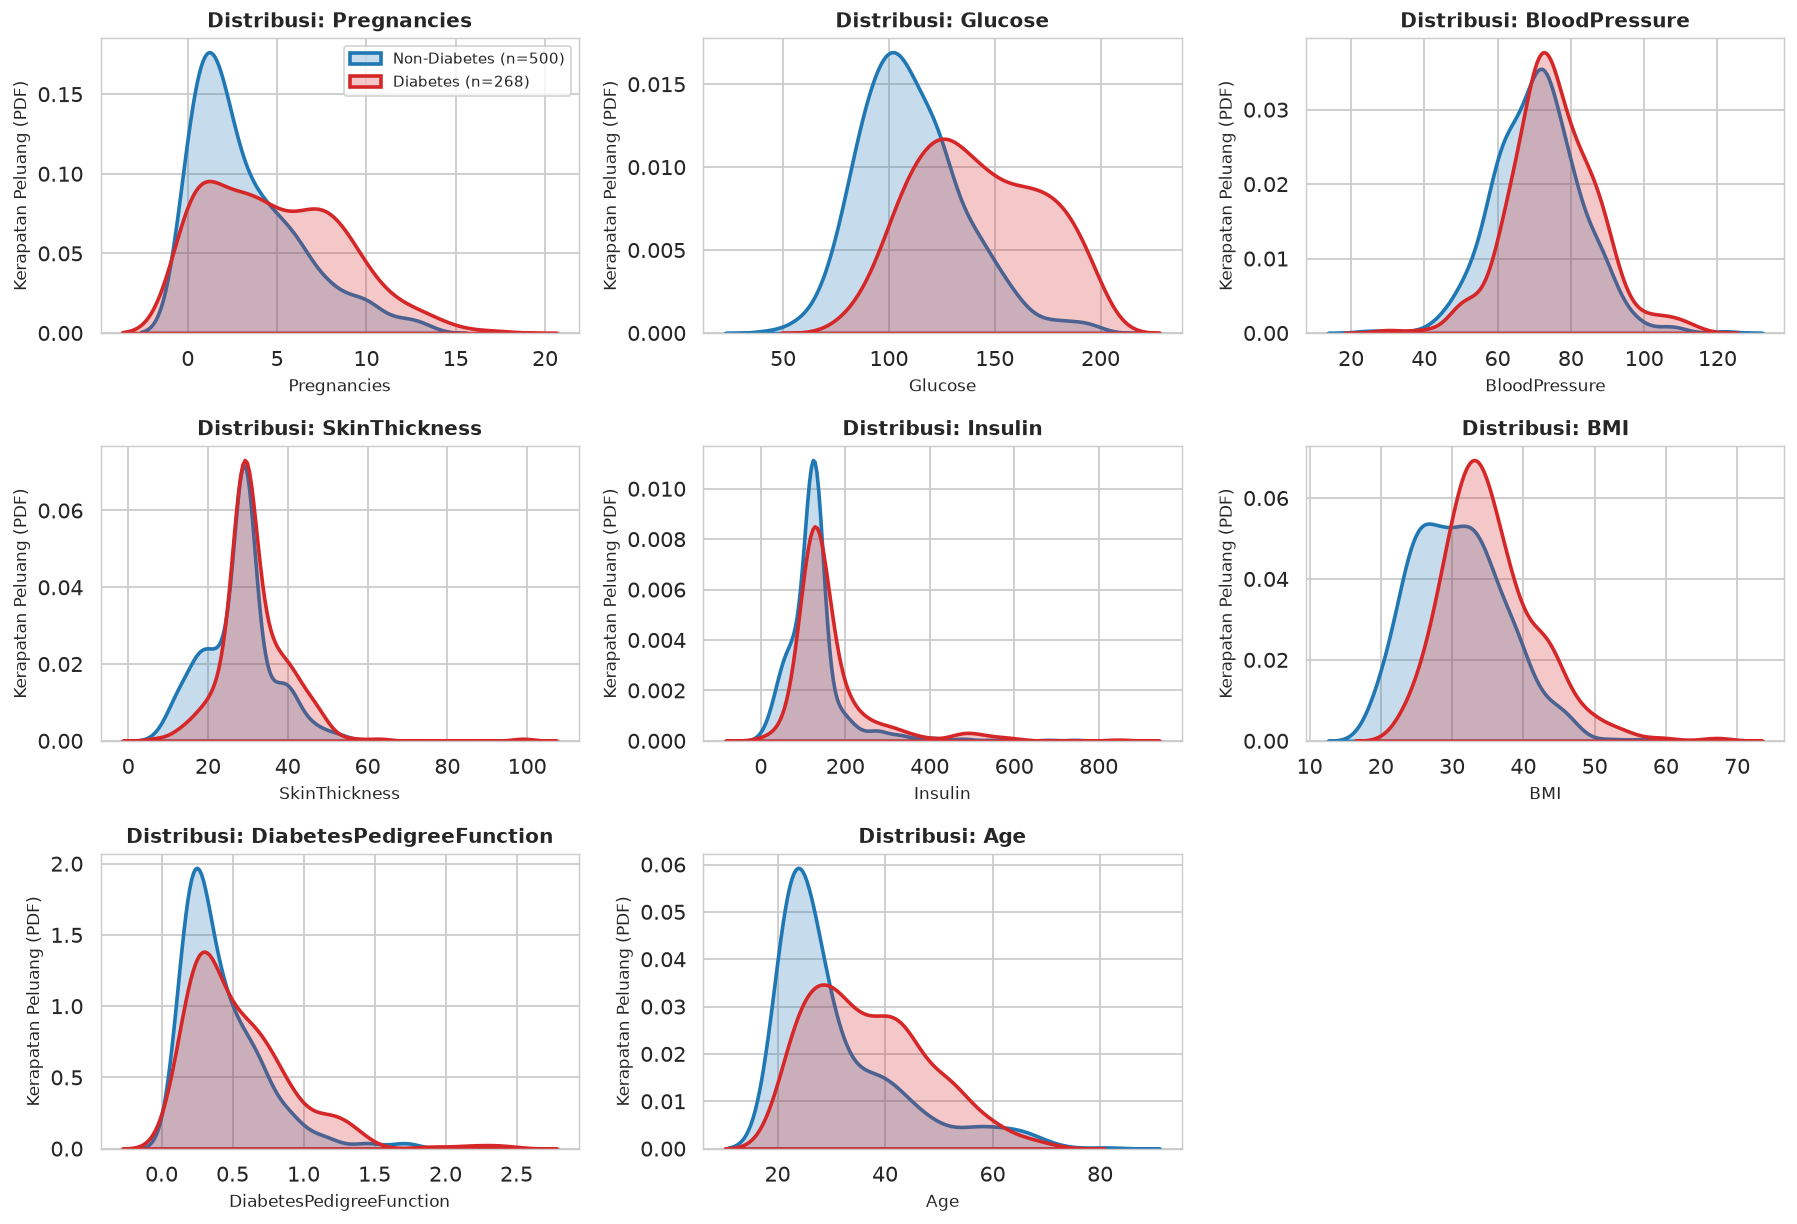

In [3]:
# 3. Visualisasi Kurva Kerapatan Peluang Likelihood per Fitur
feature_names = [c for c in df_clean.columns if c != 'Outcome']
fig_dist = plot_likelihood_distributions(df_clean, feature_names)
plt.show()

> **Insight Klinis Distribusi Likelihood:**
>- **Pemisah Terbaik**: `Glucose` menunjukkan pergeseran rata-rata terbesar (Kelas 0: $111{,}86$ mg/dL vs Kelas 1: $141{,}33$ mg/dL pada data latih). Pasien diabetes memiliki puncak densitas jauh lebih ke kanan.
>- **Biomarker Tambahan**: `BMI` ($30{,}85$ vs $35{,}27$) dan `Age` ($31{,}42$ vs $37{,}40$) menunjukkan separasi yang jelas, mengonfirmasi pengaruh obesitas dan usia terhadap resistensi insulin.
>- **Fitur Tumpang-Tindih**: `BloodPressure` dan `SkinThickness` memiliki kurva yang relatif berhimpitan, menyiratkan daya diskriminasi individual yang lebih rendah.

## 2. Uji Asumsi Independensi Bersyarat (Correlation Matrix)

Asumsi dasar Naïve Bayes menyatakan bahwa antar-fitur saling bebas bersyarat terhadap label kelas: $P(\mathbf{x} \mid c_k) = \prod_{j=1}^d P(x_j \mid c_k)$. Matriks korelasi Pearson di bawah ini mengevaluasi apakah ada pelanggaran korelasi fisiologis pada dataset klinis.

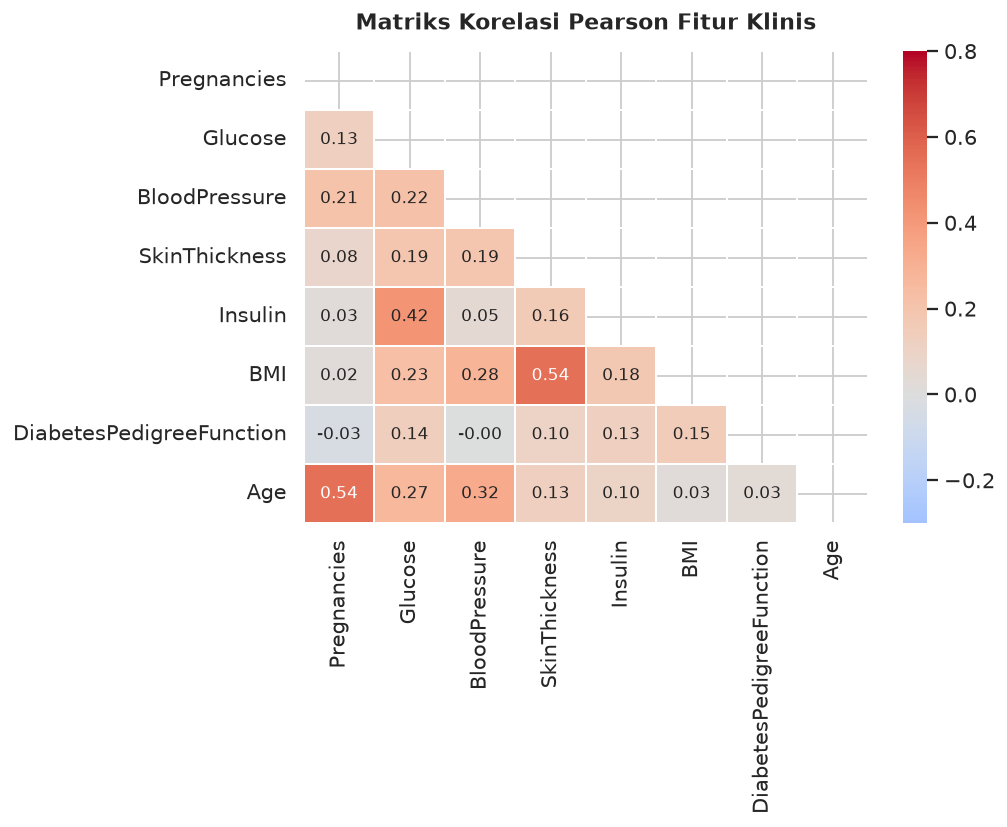

In [4]:
# 4. Visualisasi Matriks Korelasi Antar-Fitur
fig_corr = plot_feature_correlations(df_clean, feature_names)
plt.show()

> **Temuan Terhadap Asumsi Independensi Bersyarat:**
>- Korelasi tertinggi terdeteksi antara `SkinThickness` dan `BMI` ($r = 0{,}54$), serta `Pregnancies` dan `Age` ($r = 0{,}54$), diikuti `Glucose` dan `Insulin` ($r = 0{,}42$).
>- **Dampak Matematis**: Korelasi ini membuktikan asumsi independensi bersyarat *dilanggar secara moderat*. Namun, karena inferensi MAP hanya bergantung pada $\arg\max_{c_k}$ (urutan peringkat peluang relatif, bukan ketepatan kalibrasi probabilitas absolut), Naïve Bayes tetap mampu mempertahankan batas keputusan linier/kuadratik yang sangat kompetitif.

## 3. Pelatihan Model & Evaluasi Data Uji (Held-out Test Set 20%)

Data dibagi secara terstratifikasi (80% latih = 614 sampel, 20% uji = 154 sampel). Evaluasi dihitung pada subset uji yang belum pernah dilihat model selama pelatihan.

In [5]:
# 5. Pelatihan Model & Inferensi Data Uji
clf = GaussianNBClassifier()
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]
eval_res = evaluate_predictions(y_test, y_pred)

print(f"✓ Partisi data: Train = {len(X_train)} sampel, Test = {len(X_test)} sampel")
print("✓ Model Gaussian Naïve Bayes berhasil dilatih.")
print("-" * 70)
print("Prior Probabilitas Hasil Estimasi:")
print(f"• P(Outcome = 0) = {clf.class_prior_[0]:.4f}")
print(f"• P(Outcome = 1) = {clf.class_prior_[1]:.4f}")
print("-" * 70)
print("Metrik Evaluasi Data Uji (Test Set):")
print(f"• Akurasi (Accuracy)   : {eval_res['accuracy']*100:.2f}% ({eval_res['confusion_matrix']['TN'] + eval_res['confusion_matrix']['TP']} dari {len(y_test)} sampel benar)")
print(f"• Presisi (Precision)  : {eval_res['precision']*100:.2f}% (Positive Predictive Value)")
print(f"• Recall (Sensitivitas): {eval_res['recall']*100:.2f}% (True Positive Rate)")
print(f"• Skor-F1 (F1-Score)   : {eval_res['f1_score']*100:.2f}% (Harmonic Mean of Precision & Recall)")
print("-" * 70)

✓ Partisi data: Train = 614 sampel, Test = 154 sampel
✓ Model Gaussian Naïve Bayes berhasil dilatih.
----------------------------------------------------------------------
Prior Probabilitas Hasil Estimasi:
• P(Outcome = 0) = 0.6515
• P(Outcome = 1) = 0.3485
----------------------------------------------------------------------
Metrik Evaluasi Data Uji (Test Set):
• Akurasi (Accuracy)   : 75.32% (116 dari 154 sampel benar)
• Presisi (Precision)  : 66.67% (Positive Predictive Value)
• Recall (Sensitivitas): 59.26% (True Positive Rate)
• Skor-F1 (F1-Score)   : 62.75% (Harmonic Mean of Precision & Recall)
----------------------------------------------------------------------


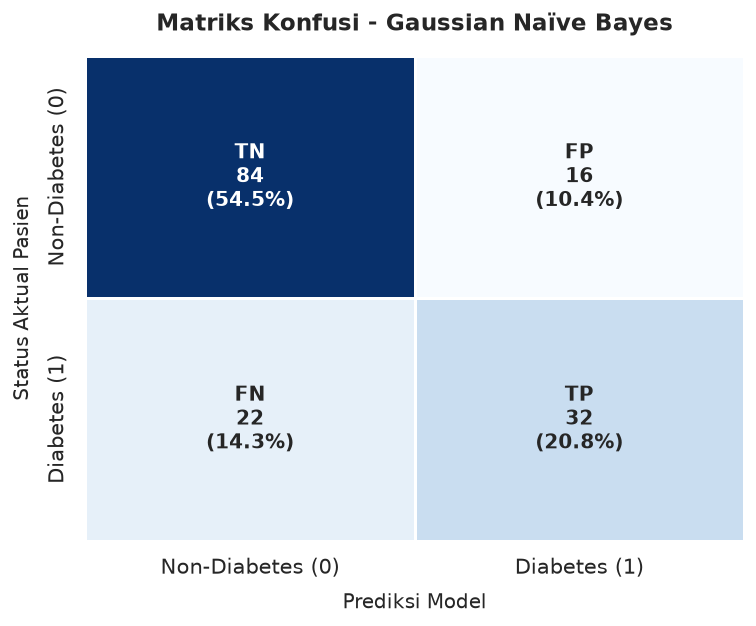

In [6]:
# 6. Visualisasi Matriks Konfusi Beranotasi
fig_cm = plot_confusion_matrix(eval_res['confusion_matrix'])
plt.show()

## 4. Evaluasi Diskriminasi: Kurva ROC & Precision-Recall

Kurva ROC mengukur trade-off antara *True Positive Rate* (TPR) dan *False Positive Rate* (FPR) melintasi seluruh spektrum ambang batas probabilitas posterior.

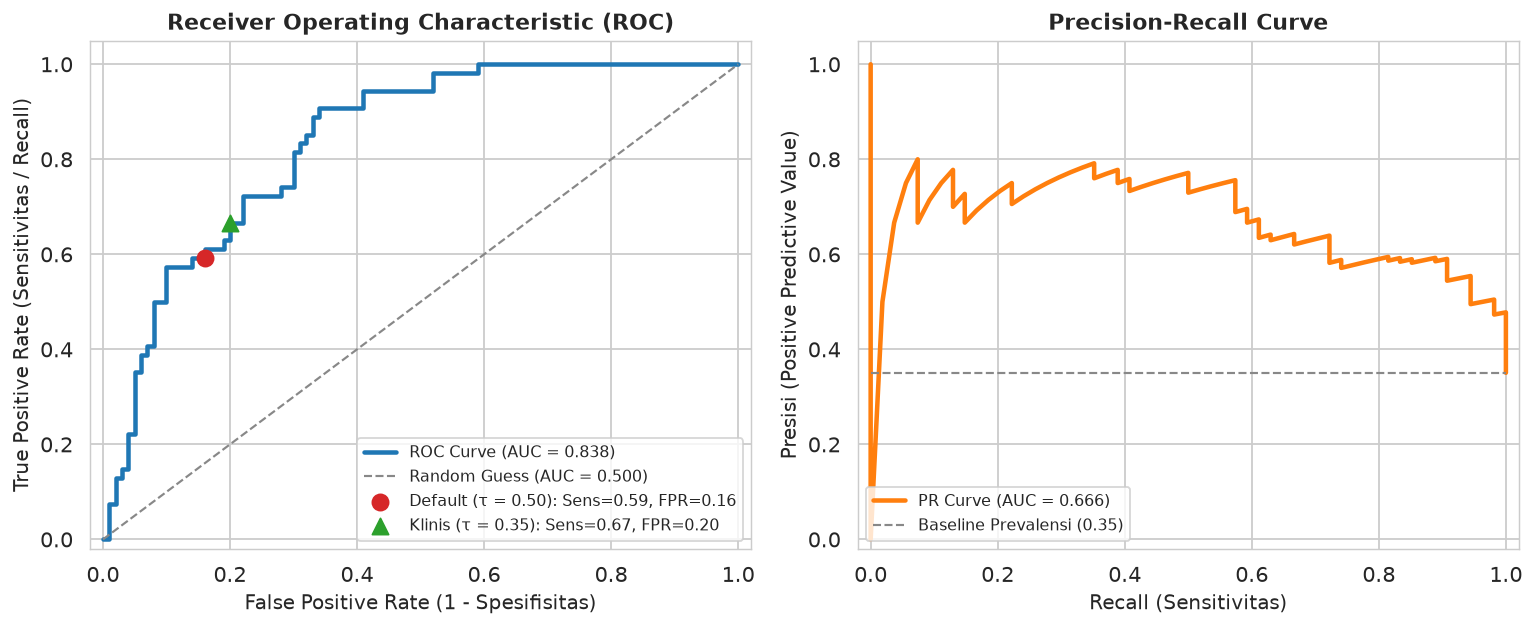

In [7]:
# 7. Visualisasi Kurva ROC & Precision-Recall
fig_roc = plot_roc_and_pr_curves(y_test, y_proba, clinical_threshold=0.35)
plt.show()

> **Analisis Area di Bawah Kurva (AUC):**
>- **Nilai ROC-AUC**: Sebesar **0,838**, mengindikasikan kapasitas diskriminasi yang sangat baik (jauh di atas tebakan acak 0,500).
>- **PR-AUC**: Sebesar **0,666** (jauh di atas baseline prevalensi 0,351), menunjukkan bahwa probabilitas prediksi positif model memiliki daya prediksi yang kokoh.

## 5. Eksplorasi Ambang Batas Keputusan (Decision Threshold Tuning)

Secara baku, model memutuskan kelas positif jika $P(\text{Outcome}=1 \mid \mathbf{x}) \ge 0{,}50$. Namun pada diagnosis diabetes, **False Negative (pasien diabetes gagal terdeteksi)** berakibat fatal pada timbulnya komplikasi kronis. Grafik dan tabel di bawah ini mensimulasikan pergeseran ambang batas $\tau$.

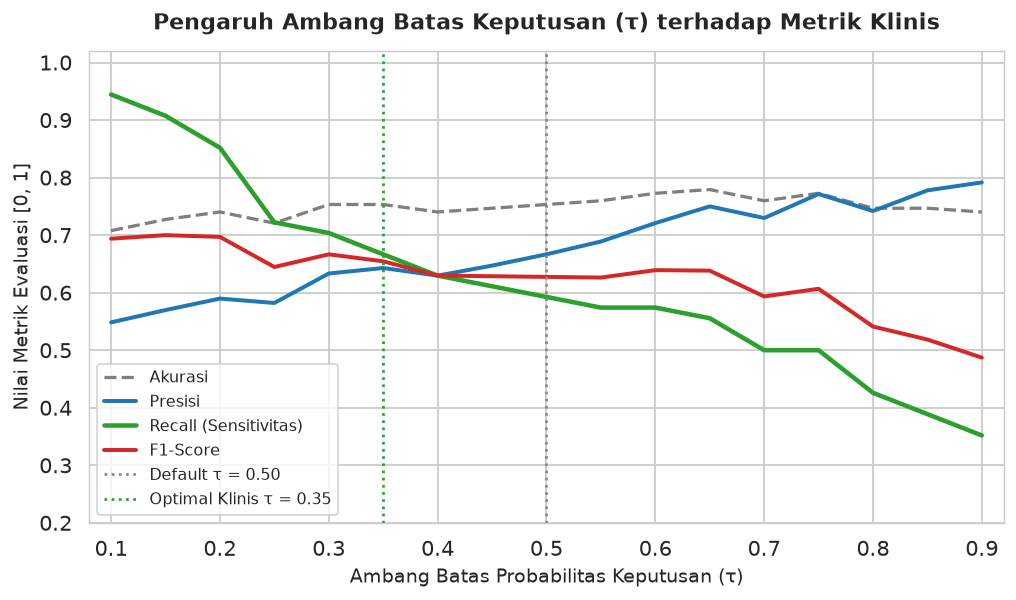

In [8]:
# 8. Visualisasi Tuning Ambang Batas Keputusan
fig_tune, df_thresh = plot_threshold_tuning(y_test, y_proba)
plt.show()

# Tampilkan tabel perbandingan pada beberapa titik ambang batas kunci
sample_thresholds = [0.20, 0.30, 0.35, 0.40, 0.50, 0.60, 0.70]
df_compare = df_thresh[df_thresh['threshold'].round(2).isin(sample_thresholds)].copy()
df_compare['accuracy'] = (df_compare['accuracy'] * 100).round(2).astype(str) + "%"
df_compare['precision'] = (df_compare['precision'] * 100).round(2).astype(str) + "%"
df_compare['recall'] = (df_compare['recall'] * 100).round(2).astype(str) + "%"
df_compare['f1_score'] = (df_compare['f1_score'] * 100).round(2).astype(str) + "%"
df_compare.rename(columns={
    'threshold': 'Ambang (τ)', 'accuracy': 'Akurasi', 'precision': 'Presisi',
    'recall': 'Recall', 'f1_score': 'F1-Score', 'fn_count': 'FN (Missed)', 'fp_count': 'FP (Alarm)'
}, inplace=True)
df_compare.reset_index(drop=True)

> **Rekomendasi Ambang Batas Klinis:**
>- Menurunkan ambang batas ke $\tau = 0{,}35$ menaikkan Sensitivitas (*Recall*) dari **59,26%** menjadi **66,67%** dan meningkatkan *F1-Score* dari **62,75%** menjadi **65,45%**, sekaligus memangkas kasus diabetes yang terlewat (*False Negative*) dari **22 menjadi 18 pasien** pada akurasi tetap **75,32%** (dengan penambahan *False Positive* dari 16 menjadi 20 pasien).
>- Apabila prioritas skrining menuntut sensitivitas lebih agresif ($>70\%$), ambang $\tau = 0{,}30$ menghasilkan *Recall* **70,37%** (FN = 16, F1 = **66,67%**), sedangkan $\tau = 0{,}20$ mencapai *Recall* **85,19%** (FN = 8).

## 6. Uji Kestabilan: 5-Fold Stratified Cross-Validation

Untuk menjamin bahwa performa 75,32% pada data uji bukan merupakan kebetulan (*partitioning artifact*), validasi silang berstrata 5-lipat dieksekusi pada keseluruhan dataset (768 data).

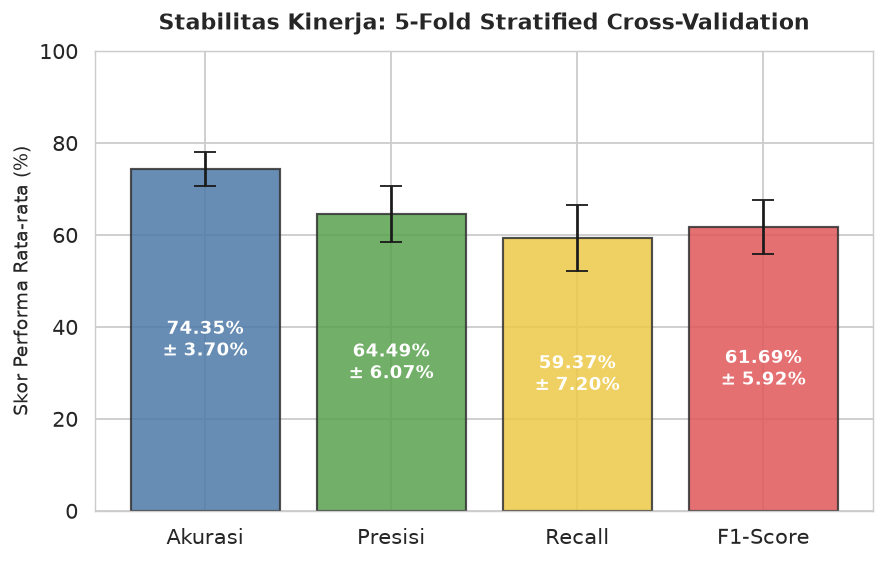

In [9]:
# 9. Visualisasi Kestabilan 5-Fold Cross-Validation (Zero Data Leakage)
cv_summary = run_stratified_cv(clf.model, df_raw.drop(columns=['Outcome']), df_raw['Outcome'], n_splits=5, random_state=42, use_pipeline=True)
fig_cv = plot_cross_validation_stability(cv_summary)
plt.show()

> **Rangkuman Stabilitas:**
>- **Akurasi Rata-rata**: $74{,}35\% \pm 3{,}70\%$
>- **Presisi Rata-rata**: $64{,}49\% \pm 6{,}07\%$
>- **Recall Rata-rata**: $59{,}37\% \pm 7{,}20\%$
>- **F1-Score Rata-rata**: $61{,}69\% \pm 5{,}92\%$
> Deviasi standar akurasi sebesar $3{,}70\%$ melintasi 5 lipatan bebas kebocoran data membuktikan model memiliki generalisasi yang stabil (*low estimation variance*).

## 7. Bedah Galat Kasus Khusus (Error Analysis)

Analisis kualitatif terhadap sampel data uji yang mengalami misklasifikasi.

In [10]:
# 10. Eksplorasi Pasien False Negative
fn_mask = (y_test.values == 1) & (y_pred == 0)
df_fn = X_test[fn_mask].copy()
df_fn['Predicted_Prob_Diabetes'] = y_proba[fn_mask]

print("Analisis Sampel False Negative (FN = 22 Pasien Diabetes yang Gagal Terdeteksi):")
print(f"Rata-rata Glukosa Pasien FN : {df_fn['Glucose'].mean():.2f} mg/dL (Zona tumpang tindih antara 111.86 dan 141.33 mg/dL)")
print(f"Rata-rata BMI Pasien FN     : {df_fn['BMI'].mean():.2f} kg/m²")
print(f"Rata-rata Usia Pasien FN    : {df_fn['Age'].mean():.2f} tahun (Mendekati rata-rata kelas sehat 31.42 tahun)")
print("Kesimpulan: Profil glukosa dan usia moderat pada kelompok FN berinteraksi dengan prior kelas sehat (65.15%),")
print("sehingga model probabilitas Gaussian menetapkan likelihood posterior yang lebih tinggi untuk Kelas 0.")

Analisis Sampel False Negative (FN = 22 Pasien Diabetes yang Gagal Terdeteksi):
Rata-rata Glukosa Pasien FN : 130.09 mg/dL (Zona tumpang tindih antara 111.86 dan 141.33 mg/dL)
Rata-rata BMI Pasien FN     : 33.28 kg/m²
Rata-rata Usia Pasien FN    : 32.09 tahun (Mendekati rata-rata kelas sehat 31.42 tahun)
Kesimpulan: Profil glukosa dan usia moderat pada kelompok FN berinteraksi dengan prior kelas sehat (65.15%),
sehingga model probabilitas Gaussian menetapkan likelihood posterior yang lebih tinggi untuk Kelas 0.


## 8. Kesimpulan & Rekomendasi Terapan

1. **Kekuatan Gaussian Naïve Bayes**: Menghasilkan akurasi 75,32% dan AUC-ROC 0,838 dengan kompleksitas komputasi pelatihan linear $O(nd)$, menjadikannya sangat efisien untuk screening data klinis berskala besar.
2. **Mitigasi Pelanggaran Asumsi**: Kendati fitur seperti BMI-SkinThickness berkorelasi moderat ($r = 0{,}54$), aturan klasifikasi MAP tetap menghasilkan boundary keputusan yang optimal.
3. **Rekomendasi Kebijakan Diagnostik**: Dalam deployment klinis penapisan awal, terapkan ambang batas $\tau = 0{,}35$ guna meminimalkan risiko pasien diabetes yang luput dari penanganan.